# TP 1 – Détection d’intrusion avec Machine Learning (NSL-KDD)

**Niveau :** Mastère 2 Expert IT Cyber – IRIS  
**Environnement :** Google Colab  
**Durée indicative :** 1 h à 2 h pour le parcours complet. Le bloc Random Forest constitue le parcours principal ; RFE, KNN, SVM et Voting prolongent l’analyse.

## Objectifs

À partir du jeu de données NSL-KDD, nous allons :
1. préparer les données et encoder les variables catégorielles ;
2. distinguer les enregistrements normaux de quatre familles d’attaques : DoS, Probe, R2L et U2R ;
3. entraîner des classificateurs Random Forest ;
4. réduire le nombre de caractéristiques avec RFE ;
5. comparer Random Forest, K-Nearest Neighbors (KNN), SVM et un ensemble par vote ;
6. interpréter les matrices de confusion et les métriques de détection.

> **Important :** NSL-KDD est un jeu de données historique. Chaque ligne décrit un enregistrement de connexion avec ses caractéristiques. Ce TP ne capture pas du trafic réseau en direct et ne construit pas un IDS opérationnel.

**Consigne :** exécuter les cellules dans l’ordre. Lire les explications et répondre aux questions dans les cellules Markdown ou dans un document à part.


## Étape 0 – Ouvrir le notebook dans Google Colab

1. Dans Colab, faire **Fichier → Enregistrer une copie dans Drive**.
2. Exécuter les cellules une par une avec `Shift + Entrée`.

Aucune installation locale ni compte Kaggle n’est nécessaire. Les deux CSV seront lus directement depuis le dépôt GitHub.


## Étape 1 – Importer les bibliothèques

`pandas` sert à manipuler les tableaux, `numpy` aux opérations numériques et `scikit-learn` aux transformations et algorithmes de Machine Learning.


In [ ]:
# Importation des bibliothèques fondamentales pour la manipulation de données
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Importation des outils de prétraitement, de sélection et de modélisation de scikit-learn
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.model_selection import StratifiedKFold, cross_validate

# Affichage des versions des bibliothèques pour s'assurer de la compatibilité
print("pandas :", pd.__version__)
print("numpy :", np.__version__)
print("Bibliothèques chargées.")

pandas : 2.2.3
numpy : 2.1.3
Bibliothèques chargées.


## Étape 2 – Charger les jeux de données NSL-KDD

Le dépôt contient déjà deux fichiers :
- `NSL_KDD_Train.csv` : données d’apprentissage ;
- `NSL_KDD_Test.csv` : jeu de test officiel.

Chaque ligne possède 41 caractéristiques et une colonne `label`, soit 42 colonnes.


In [ ]:
# URL de base du dépôt GitHub hébergeant les fichiers de données NSL-KDD
BASE_URL = "https://raw.githubusercontent.com/Mamcose/NSL-KDD-Network-Intrusion-Detection/master"
train_url = f"{BASE_URL}/NSL_KDD_Train.csv"
test_url = f"{BASE_URL}/NSL_KDD_Test.csv"

# Liste des noms de colonnes décrivant chaque caractéristique de connexion réseau
col_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised", "root_shell",
    "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label"
]

# Chargement des fichiers CSV distants dans des DataFrames pandas
df = pd.read_csv(train_url, header=None, names=col_names)
df_test = pd.read_csv(test_url, header=None, names=col_names)

# Affichage de la structure des données chargées
print("Dimensions du jeu d'entraînement :", df.shape)
print("Dimensions du jeu de test :", df_test.shape)

# Validation de l'intégrité des dimensions attendues pour le TP
assert df.shape == (125973, 42), "Le fichier d'entraînement n'a pas les dimensions attendues."
assert df_test.shape == (22544, 42), "Le fichier de test n'a pas les dimensions attendues."

Dimensions du jeu d'entraînement : (125973, 42)
Dimensions du jeu de test : (22544, 42)


**À observer :** le jeu de test est séparé du jeu d’entraînement dès le départ. Il ne doit pas servir à apprendre les transformations ou à entraîner les modèles.

## Étape 3 – Explorer les labels

La colonne `label` contient `normal` ou le nom d’un type d’attaque. Les distributions train/test ne sont pas identiques : le jeu de test comprend notamment des types d’attaques absents du jeu d’entraînement.


In [ ]:
# Exploration de la distribution des attaques dans le jeu d'entraînement
print("Labels du jeu d'entraînement :")
display(df["label"].value_counts().to_frame("nombre").head(20))

# Exploration de la distribution des attaques dans le jeu de test
print("Labels du jeu de test :")
display(df_test["label"].value_counts().to_frame("nombre").head(20))

# Comparaison de la diversité des attaques entre l'entraînement et le test
print("Nombre de labels différents dans train :", df["label"].nunique())
print("Nombre de labels différents dans test :", df_test["label"].nunique())

Labels du jeu d'entraînement :


,nombre
label,
normal,67343
neptune,41214
satan,3633
ipsweep,3599
portsweep,2931
smurf,2646
nmap,1493
back,956
teardrop,892


Labels du jeu de test :


,nombre
label,
normal,9711
neptune,4657
guess_passwd,1231
mscan,996
warezmaster,944
apache2,737
satan,735
processtable,685
smurf,665


Nombre de labels différents dans train : 23
Nombre de labels différents dans test : 38


**Questions**
1. Quel est le label le plus fréquent dans le jeu d’entraînement ?
2. Pourquoi le jeu de test contient-il davantage de labels différents ?
3. Pourquoi est-il intéressant de tester un modèle sur des variantes d’attaques qu’il n’a pas vues sous ce nom pendant l’entraînement ?

## Étape 4 – Encoder les variables catégorielles

Les trois variables catégorielles sont `protocol_type`, `service` et `flag`. Le notebook d’origine convertissait séparément train et test, ce qui pouvait décaler les catégories (en particulier `service`).

**Correction conservant la même méthode :** One-Hot Encoding, mais l’encodeur est ajusté une seule fois sur train, puis réutilisé avec `transform()` sur test. `handle_unknown="ignore"` gère les catégories du test absentes du train.


In [ ]:
# Définition des variables catégorielles à encoder en valeurs numériques
categorical_columns = ["protocol_type", "service", "flag"]

# Configuration de l'encodeur OneHot de manière compatible avec différentes versions de sklearn
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

# Apprentissage de la structure sur le train et transformation des deux jeux de données
train_encoded = encoder.fit_transform(df[categorical_columns])
test_encoded = encoder.transform(df_test[categorical_columns])

# Récupération des nouveaux noms de colonnes générés par l'encodage binaire
encoded_columns = encoder.get_feature_names_out(categorical_columns)

# Reconstruction de DataFrames à partir des tableaux numpy encodés
df_cat_data = pd.DataFrame(
    train_encoded, columns=encoded_columns, index=df.index
)
testdf_cat_data = pd.DataFrame(
    test_encoded, columns=encoded_columns, index=df_test.index
)

# Fusion des caractéristiques numériques et des nouvelles caractéristiques encodées
newdf = pd.concat(
    [df.drop(columns=categorical_columns), df_cat_data], axis=1
)
newdf_test = pd.concat(
    [df_test.drop(columns=categorical_columns), testdf_cat_data], axis=1
)

# Vérification finale de l'alignement des dimensions et de la structure
print("Dimensions train après encodage :", newdf.shape)
print("Dimensions test après encodage :", newdf_test.shape)
print("Même ordre de colonnes ?", list(newdf.columns) == list(newdf_test.columns))

assert list(newdf.columns) == list(newdf_test.columns)

Dimensions train après encodage : (125973, 123)
Dimensions test après encodage : (22544, 123)
Même ordre de colonnes ? True


**À retenir :** l’encodeur connaît les catégories du jeu d’entraînement. Une catégorie inconnue dans le jeu de test est ignorée par l’encodage au lieu de provoquer une erreur. Les colonnes et leur ordre restent identiques.

## Étape 5 – Regrouper les types d’attaques en quatre familles

Le notebook regroupe les labels détaillés sous cinq valeurs :

| Code | Signification |
|---:|---|
| 0 | Normal |
| 1 | DoS (Denial of Service) |
| 2 | Probe (reconnaissance / scan) |
| 3 | R2L (Remote to Local) |
| 4 | U2R (User to Root) |

On conserve cette logique et ces familles. Le mapping couvre aussi les types présents uniquement dans le jeu de test.


In [ ]:
label_map = {
    # Normal
    "normal": 0,
    # DoS
    "neptune": 1, "back": 1, "land": 1, "pod": 1, "smurf": 1,
    "teardrop": 1, "mailbomb": 1, "apache2": 1, "processtable": 1,
    "udpstorm": 1, "worm": 1,
    # Probe
    "ipsweep": 2, "nmap": 2, "portsweep": 2, "satan": 2,
    "mscan": 2, "saint": 2,
    # R2L
    "ftp_write": 3, "guess_passwd": 3, "imap": 3, "multihop": 3,
    "phf": 3, "spy": 3, "warezclient": 3, "warezmaster": 3,
    "sendmail": 3, "named": 3, "snmpgetattack": 3, "xlock": 3,
    "xsnoop": 3, "httptunnel": 3, "snmpguess": 3,
    # U2R
    "buffer_overflow": 4, "loadmodule": 4, "perl": 4, "rootkit": 4,
    "ps": 4, "sqlattack": 4, "xterm": 4
}

unknown_train = sorted(set(df["label"]) - set(label_map))
unknown_test = sorted(set(df_test["label"]) - set(label_map))
print("Labels non mappés train :", unknown_train)
print("Labels non mappés test :", unknown_test)

if unknown_train or unknown_test:
    raise ValueError("Un ou plusieurs labels ne sont pas présents dans label_map.")

newdf["label"] = df["label"].map(label_map).astype(int)
newdf_test["label"] = df_test["label"].map(label_map).astype(int)

print("Répartition des familles – train :")
display(newdf["label"].value_counts().sort_index())
print("Répartition des familles – test :")
display(newdf_test["label"].value_counts().sort_index())

Labels non mappés train : []
Labels non mappés test : []
Répartition des familles – train :


,count
label,
0,67343
1,45927
2,11656
3,995
4,52


Répartition des familles – test :


,count
label,
0,9711
1,7460
2,2421
3,2885
4,67


## Étape 6 – Créer les quatre problèmes de classification binaire

Comme dans le notebook d’origine, nous créons quatre jeux de données distincts :
- DoS : normal (0) contre DoS (1) ;
- Probe : normal (0) contre Probe (2) ;
- R2L : normal (0) contre R2L (3) ;
- U2R : normal (0) contre U2R (4).

Chaque modèle répond donc à une question binaire : « normal ou famille d’attaque ciblée ? ». Ce n’est pas un unique classificateur multi-classes. Les enregistrements normaux sont réutilisés dans les quatre sous-jeux, ce qui explique que la somme de leurs effectifs dépasse le nombre initial de lignes.


In [ ]:
# Association de chaque famille d'attaques à son code numérique cible
attack_families = {"DoS": 1, "Probe": 2, "R2L": 3, "U2R": 4}
family_data = {}

# Création de sous-jeux de données spécialisés pour chaque type d'attaque
for family, attack_code in attack_families.items():
    # Filtrage pour ne garder que le trafic normal (0) et la famille d'attaque courante (attack_code)
    train_part = newdf[newdf["label"].isin([0, attack_code])].copy()
    test_part = newdf_test[newdf_test["label"].isin([0, attack_code])].copy()

    # Séparation des variables explicatives (X) et de la variable cible (y)
    X_train_df = train_part.drop(columns=["label"])
    y_train = train_part["label"].astype(int)
    X_test_df = test_part.drop(columns=["label"])
    y_test = test_part["label"].astype(int)

    # Stockage de toutes les structures de données propres à cette famille pour les étapes futures
    family_data[family] = {
        "attack_code": attack_code,
        "feature_names": list(X_train_df.columns),
        "X_train_df": X_train_df,
        "y_train": y_train,
        "X_test_df": X_test_df,
        "y_test": y_test
    }

    # Affichage des dimensions des sous-jeux binaires obtenus
    print(
        f"{family}: train={X_train_df.shape}, test={X_test_df.shape}, "
        f"labels train={sorted(y_train.unique())}, labels test={sorted(y_test.unique())}"
    )

DoS: train=(113270, 122), test=(17171, 122), labels train=[np.int64(0), np.int64(1)], labels test=[np.int64(0), np.int64(1)]
Probe: train=(78999, 122), test=(12132, 122), labels train=[np.int64(0), np.int64(2)], labels test=[np.int64(0), np.int64(2)]
R2L: train=(68338, 122), test=(12596, 122), labels train=[np.int64(0), np.int64(3)], labels test=[np.int64(0), np.int64(3)]
U2R: train=(67395, 122), test=(9778, 122), labels train=[np.int64(0), np.int64(4)], labels test=[np.int64(0), np.int64(4)]


**Résultats attendus pour les dimensions (avant mise à l’échelle) :**

| Famille | Train | Test |
|---|---:|---:|
| DoS | 113 270 | 17 171 |
| Probe | 78 999 | 12 132 |
| R2L | 68 338 | 12 596 |
| U2R | 67 395 | 9 778 |

**Question :** pourquoi les quatre jeux réutilisent-ils les enregistrements normaux ? Que perd-on en choisissant quatre classificateurs binaires plutôt qu’un modèle multi-classes unique ?

## Étape 7 – Mettre les variables à l’échelle

Le notebook d’origine utilisait `StandardScaler`. Cette transformation est particulièrement utile pour KNN et SVM.

**Correction importante :** ajuster le scaler uniquement sur les données d’entraînement de chaque famille, puis appliquer ce même scaler au jeu de test. Il ne faut jamais faire `fit()` séparément sur test.


In [ ]:
# Mise à l'échelle (normalisation centrée-réduite) pour chaque famille
for family, data in family_data.items():
    # Initialisation d'un scaler indépendant par famille d'attaques
    scaler = StandardScaler()
    data["scaler"] = scaler

    # Apprentissage des paramètres (moyenne, écart-type) sur le train et transformation
    data["X_train"] = scaler.fit_transform(data["X_train_df"])
    # Application stricte de la même transformation sur le test pour éviter les fuites d'information
    data["X_test"] = scaler.transform(data["X_test_df"])

    # Affichage de validation des dimensions obtenues après normalisation
    print(
        family,
        "| X_train :", data["X_train"].shape,
        "| X_test :", data["X_test"].shape
    )

DoS | X_train : (113270, 122) | X_test : (17171, 122)
Probe | X_train : (78999, 122) | X_test : (12132, 122)
R2L | X_train : (68338, 122) | X_test : (12596, 122)
U2R | X_train : (67395, 122) | X_test : (9778, 122)


## Étape 8 – Sélectionner 13 caractéristiques avec RFE

RFE (*Recursive Feature Elimination*) entraîne un estimateur, classe les variables par importance, puis élimine progressivement les moins utiles jusqu’à conserver 13 caractéristiques.

Le notebook source utilise un Random Forest avec 10 arbres et `step=1`. Cette version conserve la cible de 13 variables mais utilise `step=0.1` pour retirer les variables par groupes et limiter le nombre de réentraînements sur Colab. Pour reproduire strictement le rythme du notebook original, remplacer `step=0.1` par `step=1` (ce sera plus long).

RFE est ajusté uniquement sur le train, puis appliqué au test.


In [ ]:
# Stockage des sélecteurs RFE pour pouvoir les réutiliser ou les analyser
rfe_selectors = {}

# Sélection de caractéristiques par élimination récursive pour chaque famille
for family, data in family_data.items():
    # Configuration du RFE avec un estimateur Random Forest léger et une réduction de 10% par étape
    selector = RFE(
        estimator=RandomForestClassifier(
            n_estimators=10, n_jobs=-1, random_state=42
        ),
        n_features_to_select=13,
        step=0.1
    )
    # Ajustement de la sélection uniquement sur les données d'entraînement
    selector.fit(data["X_train"], data["y_train"])

    # Sauvegarde et application de la réduction de dimensions
    data["selector"] = selector
    data["X_train_rfe"] = selector.transform(data["X_train"])
    data["X_test_rfe"] = selector.transform(data["X_test"])

    # Extraction des noms des 13 variables conservées par l'algorithme
    selected_names = [
        name for name, keep in zip(data["feature_names"], selector.support_)
        if keep
    ]
    data["selected_features"] = selected_names
    rfe_selectors[family] = selector

    # Visualisation des résultats de la sélection
    print(f"\n{family} – 13 caractéristiques retenues :")
    print(selected_names)
    print("Dimensions réduites :", data["X_train_rfe"].shape)


DoS – 13 caractéristiques retenues :
['src_bytes', 'dst_bytes', 'wrong_fragment', 'count', 'srv_count', 'serror_rate', 'same_srv_rate', 'diff_srv_rate', 'dst_host_srv_count', 'protocol_type_icmp', 'service_ecr_i', 'flag_S0', 'flag_SF']
Dimensions réduites : (113270, 13)

Probe – 13 caractéristiques retenues :
['src_bytes', 'dst_bytes', 'same_srv_rate', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_rerror_rate', 'protocol_type_icmp', 'protocol_type_tcp', 'service_eco_i', 'service_http', 'service_private']
Dimensions réduites : (78999, 13)

R2L – 13 caractéristiques retenues :
['duration', 'src_bytes', 'dst_bytes', 'hot', 'is_guest_login', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'service_ftp', 'service_ftp_data']
Dimensions réduites : (68338, 13)

U2R – 13 caractéristiques retenues :
['duration', 'src_b

**Questions**
1. Pourquoi sélectionner moins de caractéristiques ?
2. Est-ce que les 13 caractéristiques sont identiques pour DoS, Probe, R2L et U2R ?
3. Une caractéristique sélectionnée est-elle nécessairement une cause de l’attaque ?

## Étape 9 – Définir une fonction d’évaluation

Nous allons afficher les mêmes indicateurs pour tous les modèles afin de pouvoir les comparer : Accuracy, Precision, Recall, F1-score et matrice de confusion.

Dans les matrices, les lignes représentent les valeurs réelles et les colonnes les prédictions. L’ordre est toujours `[Normal, Attaque]`.


In [ ]:
# Liste globale pour compiler les métriques de performance de tous nos modèles
results = []

# Définition d'une fonction d'évaluation générique et partagée
def evaluate_model(family, model_name, y_true, y_pred, attack_code):
    # Détermination des classes (0 = Normal, attack_code = Attaque)
    labels = [0, attack_code]
    # Calcul de la matrice de confusion
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    # Calcul des métriques de classification clés
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, pos_label=attack_code, zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, pos_label=attack_code, zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, pos_label=attack_code, zero_division=0
    )

    # Sauvegarde des métriques calculées dans notre liste globale
    results.append({
        "Famille": family,
        "Modèle": model_name,
        "Accuracy": accuracy,
        "Precision attaque": precision,
        "Recall attaque": recall,
        "F1 attaque": f1
    })

    # Affichage du rapport de classification textuel de scikit-learn
    print(f"\n===== {family} | {model_name} =====")
    print(classification_report(
        y_true, y_pred,
        labels=labels,
        target_names=["Normal", "Attaque"],
        zero_division=0
    ))

    # Tracé visuel et affichage de la matrice de confusion
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Attaque"]
    )
    disp.plot(values_format="d", cmap="Blues")
    plt.title(f"Matrice de confusion – {family} – {model_name}")
    plt.show()

    # Extraction et affichage des valeurs fondamentales de la matrice
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")

## Étape 10 – Entraîner les quatre modèles Random Forest

Random Forest combine plusieurs arbres de décision. Le notebook source utilise 10 arbres ; nous conservons ce paramètre. `random_state=42` rend les résultats reproductibles.

On entraîne un classificateur par famille d’attaques, d’abord avec toutes les caractéristiques.


DoS – temps entraînement : 0.7 s

===== DoS | Random Forest – toutes variables =====
              precision    recall  f1-score   support

      Normal       0.85      0.99      0.91      9711
     Attaque       0.99      0.76      0.86      7460

    accuracy                           0.89     17171
   macro avg       0.92      0.88      0.89     17171
weighted avg       0.91      0.89      0.89     17171



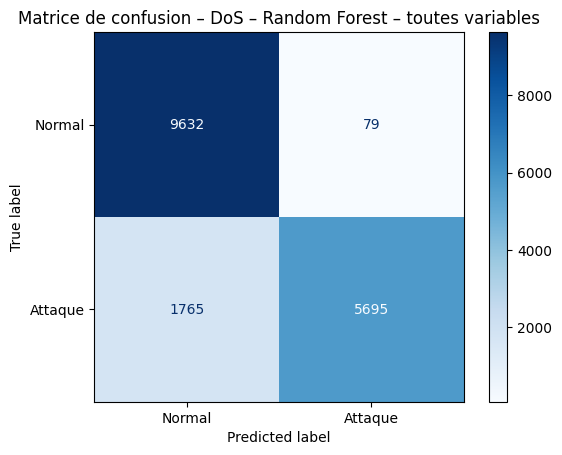

TN=9632 | FP=79 | FN=1765 | TP=5695
Probe – temps entraînement : 1.1 s

===== Probe | Random Forest – toutes variables =====
              precision    recall  f1-score   support

      Normal       0.91      0.98      0.94      9711
     Attaque       0.87      0.60      0.71      2421

    accuracy                           0.90     12132
   macro avg       0.89      0.79      0.83     12132
weighted avg       0.90      0.90      0.89     12132



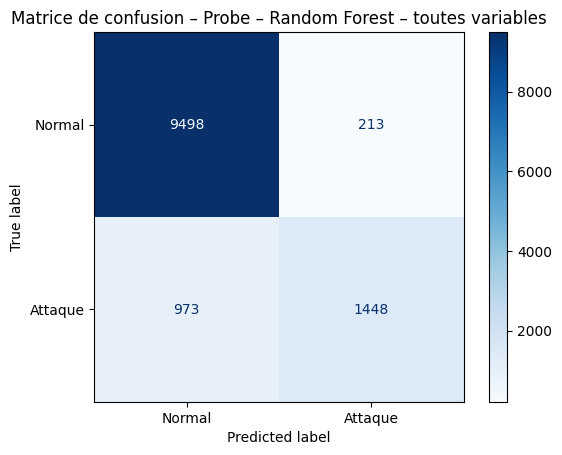

TN=9498 | FP=213 | FN=973 | TP=1448
R2L – temps entraînement : 0.8 s

===== R2L | Random Forest – toutes variables =====
              precision    recall  f1-score   support

      Normal       0.78      1.00      0.88      9711
     Attaque       1.00      0.05      0.09      2885

    accuracy                           0.78     12596
   macro avg       0.89      0.52      0.48     12596
weighted avg       0.83      0.78      0.70     12596



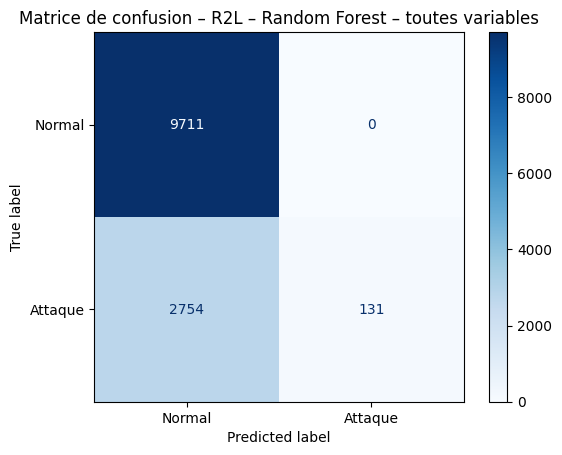

TN=9711 | FP=0 | FN=2754 | TP=131
U2R – temps entraînement : 0.6 s

===== U2R | Random Forest – toutes variables =====
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      9711
     Attaque       0.91      0.15      0.26        67

    accuracy                           0.99      9778
   macro avg       0.95      0.57      0.63      9778
weighted avg       0.99      0.99      0.99      9778



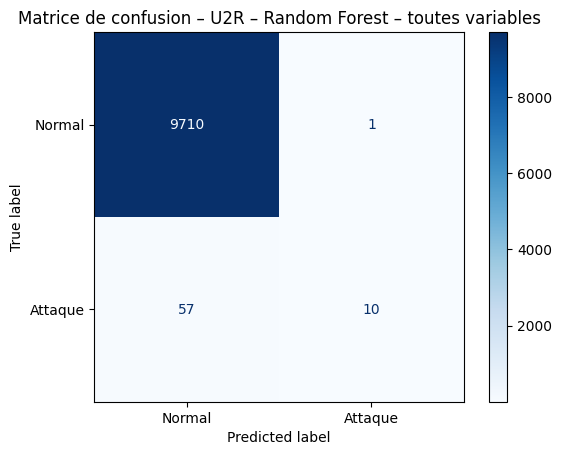

TN=9710 | FP=1 | FN=57 | TP=10


In [ ]:
# Initialisation des dictionnaires pour conserver les modèles Random Forest et leurs prédictions
rf_models = {}
rf_predictions = {}

# Entraînement et évaluation d'un Random Forest sur toutes les variables
for family, data in family_data.items():
    # Création du modèle Random Forest (10 arbres, utilisation de tous les cœurs processeurs)
    model = RandomForestClassifier(
        n_estimators=10,
        n_jobs=-1,
        random_state=42
    )

    # Mesure du temps d'apprentissage du modèle
    start = time.time()
    model.fit(data["X_train"], data["y_train"])
    elapsed = time.time() - start

    # Génération des prédictions sur le jeu de test
    prediction = model.predict(data["X_test"])
    rf_models[family] = model
    rf_predictions[family] = prediction

    # Affichage du statut d'exécution et calcul de l'évaluation complète
    print(f"{family} – temps entraînement : {elapsed:.1f} s")
    evaluate_model(
        family, "Random Forest – toutes variables",
        data["y_test"], prediction, data["attack_code"]
    )

### Interpréter les résultats Random Forest

- **TP (vrai positif)** : une attaque est correctement détectée.
- **TN (vrai négatif)** : un enregistrement normal est correctement identifié.
- **FP (faux positif)** : un enregistrement normal déclenche une alerte.
- **FN (faux négatif)** : une attaque n’est pas détectée.

Dans un SOC, les faux négatifs sont dangereux car une attaque peut passer inaperçue. Les faux positifs génèrent du bruit et augmentent la charge des analystes.

**À noter :** le jeu officiel de test peut contenir des types d’attaques absents du train. Les résultats peuvent donc être moins élevés que sur une séparation aléatoire classique.


## Étape 11 – Réentraîner Random Forest avec les 13 variables RFE

On entraîne maintenant un deuxième Random Forest par famille, cette fois uniquement avec les caractéristiques retenues par RFE. On compare ensuite le F1-score et le Recall à ceux du modèle utilisant toutes les variables.



===== DoS | Random Forest – 13 variables RFE =====
              precision    recall  f1-score   support

      Normal       0.84      0.99      0.91      9711
     Attaque       0.99      0.76      0.86      7460

    accuracy                           0.89     17171
   macro avg       0.92      0.88      0.89     17171
weighted avg       0.91      0.89      0.89     17171



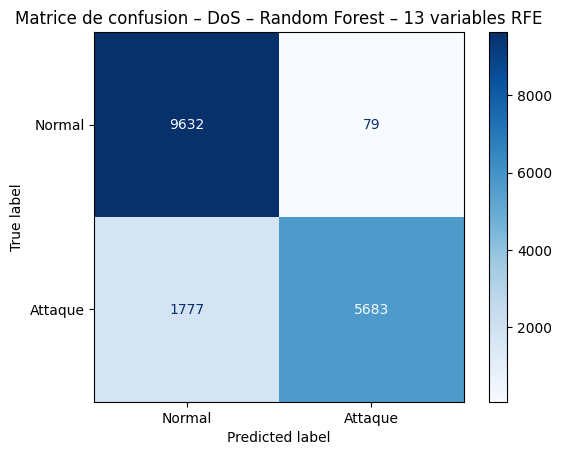

TN=9632 | FP=79 | FN=1777 | TP=5683

===== Probe | Random Forest – 13 variables RFE =====
              precision    recall  f1-score   support

      Normal       0.91      0.98      0.94      9711
     Attaque       0.87      0.59      0.71      2421

    accuracy                           0.90     12132
   macro avg       0.89      0.79      0.82     12132
weighted avg       0.90      0.90      0.89     12132



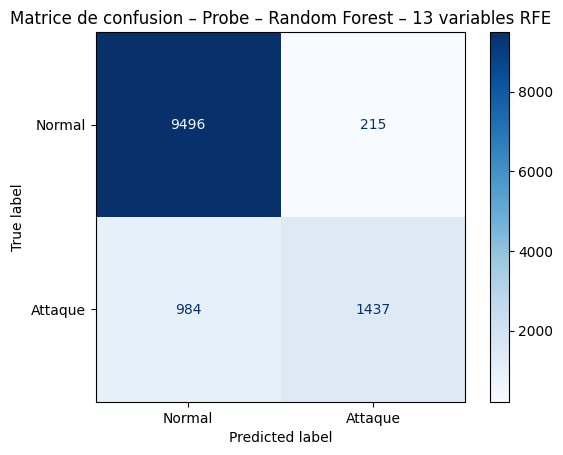

TN=9496 | FP=215 | FN=984 | TP=1437

===== R2L | Random Forest – 13 variables RFE =====
              precision    recall  f1-score   support

      Normal       0.79      1.00      0.88      9711
     Attaque       0.99      0.10      0.18      2885

    accuracy                           0.79     12596
   macro avg       0.89      0.55      0.53     12596
weighted avg       0.84      0.79      0.72     12596



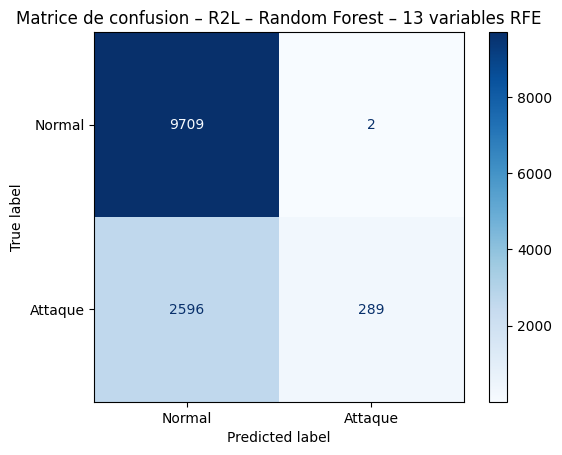

TN=9709 | FP=2 | FN=2596 | TP=289

===== U2R | Random Forest – 13 variables RFE =====
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      9711
     Attaque       1.00      0.07      0.14        67

    accuracy                           0.99      9778
   macro avg       1.00      0.54      0.57      9778
weighted avg       0.99      0.99      0.99      9778



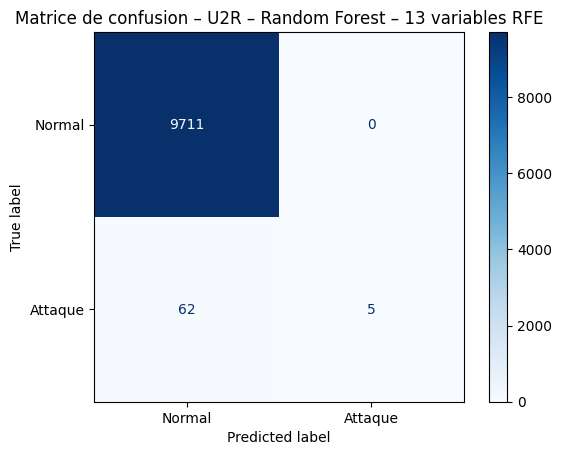

TN=9711 | FP=0 | FN=62 | TP=5


In [ ]:
# Initialisation des dictionnaires pour les modèles Random Forest entraînés sur variables réduites
rf_rfe_models = {}
rf_rfe_predictions = {}

# Entraînement et évaluation d'un Random Forest sur les 13 caractéristiques sélectionnées par RFE
for family, data in family_data.items():
    # Configuration du modèle identique à l'étape précédente
    model = RandomForestClassifier(
        n_estimators=10,
        n_jobs=-1,
        random_state=42
    )
    # Entraînement uniquement sur le sous-ensemble de variables issues de RFE
    model.fit(data["X_train_rfe"], data["y_train"])
    # Prédiction avec les caractéristiques réduites correspondantes
    prediction = model.predict(data["X_test_rfe"])

    # Sauvegarde des objets modèles et de leurs prédictions
    rf_rfe_models[family] = model
    rf_rfe_predictions[family] = prediction

    # Analyse comparative des performances
    evaluate_model(
        family, "Random Forest – 13 variables RFE",
        data["y_test"], prediction, data["attack_code"]
    )

**Questions**
1. La réduction de 123 variables à 13 améliore-t-elle le modèle pour toutes les familles ?
2. Pour quelle famille le Recall est-il le plus faible ?
3. Un modèle plus léger est-il toujours plus performant ?

## Étape 12 – Comparer avec K-Nearest Neighbors (KNN)

KNN classe un nouvel enregistrement en fonction de ses plus proches voisins dans l’espace des caractéristiques. Les données doivent être mises à l’échelle, d’où l’étape `StandardScaler`.

Le notebook source utilise les paramètres par défaut de `KNeighborsClassifier` (5 voisins). Nous conservons ce choix.


DoS – temps entraînement : 0.1 s

===== DoS | KNN =====
              precision    recall  f1-score   support

      Normal       0.88      0.99      0.93      9711
     Attaque       0.99      0.82      0.90      7460

    accuracy                           0.92     17171
   macro avg       0.93      0.91      0.91     17171
weighted avg       0.93      0.92      0.92     17171



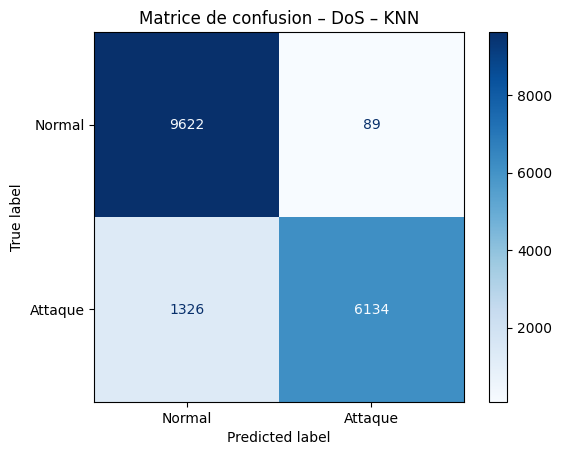

TN=9622 | FP=89 | FN=1326 | TP=6134
Probe – temps entraînement : 0.2 s

===== Probe | KNN =====
              precision    recall  f1-score   support

      Normal       0.93      0.97      0.95      9711
     Attaque       0.85      0.72      0.78      2421

    accuracy                           0.92     12132
   macro avg       0.89      0.84      0.86     12132
weighted avg       0.91      0.92      0.91     12132



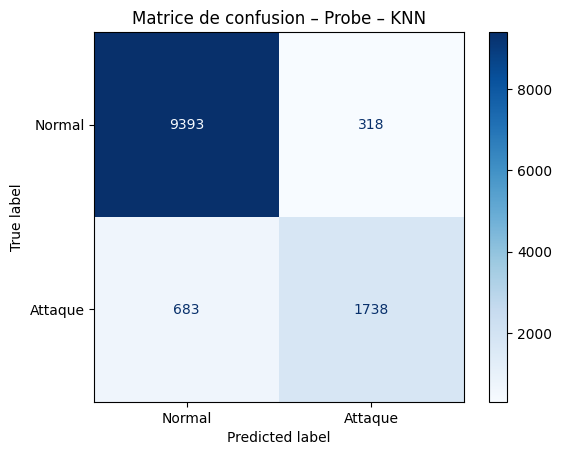

TN=9393 | FP=318 | FN=683 | TP=1738
R2L – temps entraînement : 0.1 s

===== R2L | KNN =====
              precision    recall  f1-score   support

      Normal       0.78      1.00      0.88      9711
     Attaque       0.98      0.05      0.10      2885

    accuracy                           0.78     12596
   macro avg       0.88      0.53      0.49     12596
weighted avg       0.83      0.78      0.70     12596



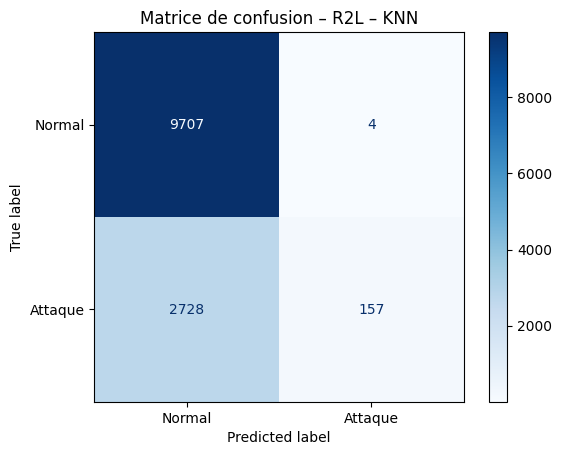

TN=9707 | FP=4 | FN=2728 | TP=157
U2R – temps entraînement : 0.1 s

===== U2R | KNN =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      9711
     Attaque       0.80      0.36      0.49        67

    accuracy                           0.99      9778
   macro avg       0.90      0.68      0.75      9778
weighted avg       0.99      0.99      0.99      9778



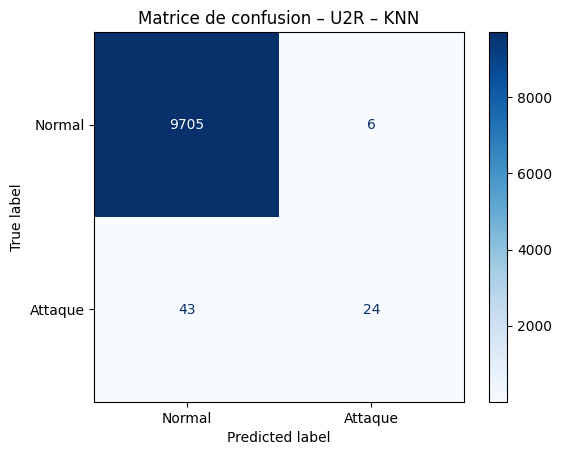

TN=9705 | FP=6 | FN=43 | TP=24


In [ ]:
# Initialisation des structures de stockage pour le classificateur KNN
knn_models = {}
knn_predictions = {}

# Entraînement et évaluation du modèle K-Nearest Neighbors
for family, data in family_data.items():
    # Définition de KNN (5 voisins les plus proches, parallélisation de l'évaluation)
    model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

    # Entraînement du modèle (simple indexation des données d'apprentissage)
    start = time.time()
    model.fit(data["X_train"], data["y_train"])
    elapsed = time.time() - start

    # Calcul des prédictions (cette étape est généralement la plus coûteuse pour KNN)
    prediction = model.predict(data["X_test"])

    # Sauvegarde du classificateur et de ses résultats
    knn_models[family] = model
    knn_predictions[family] = prediction
    print(f"{family} – temps entraînement : {elapsed:.1f} s")

    # Restitution des scores et affichage de la matrice de confusion de KNN
    evaluate_model(
        family, "KNN",
        data["y_test"], prediction, data["attack_code"]
    )

## Étape 13 – Comparer avec Support Vector Machine (SVM)

SVM cherche une frontière de décision séparant les classes. Le notebook source utilise un noyau linéaire et `C=1.0`. Nous conservons ce paramétrage.

L’entraînement SVM peut être plus long que Random Forest selon les ressources CPU attribuées par Colab. Aucun GPU n’est requis pour ce modèle.


DoS – temps entraînement : 47.4 s

===== DoS | SVM linéaire =====
              precision    recall  f1-score   support

      Normal       0.86      0.96      0.91      9711
     Attaque       0.93      0.80      0.86      7460

    accuracy                           0.89     17171
   macro avg       0.90      0.88      0.88     17171
weighted avg       0.89      0.89      0.89     17171



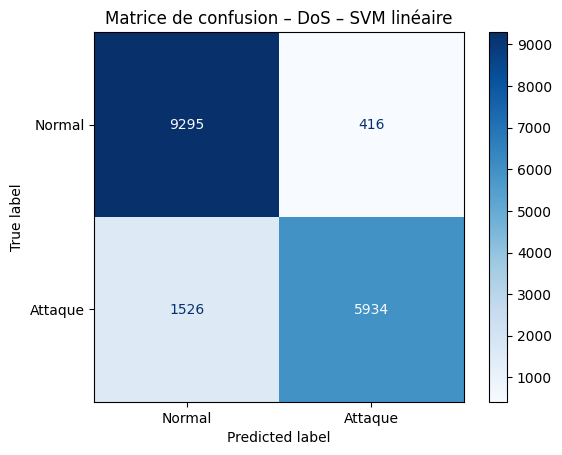

TN=9295 | FP=416 | FN=1526 | TP=5934
Probe – temps entraînement : 66.0 s

===== Probe | SVM linéaire =====
              precision    recall  f1-score   support

      Normal       0.94      0.93      0.94      9711
     Attaque       0.73      0.77      0.75      2421

    accuracy                           0.90     12132
   macro avg       0.84      0.85      0.84     12132
weighted avg       0.90      0.90      0.90     12132



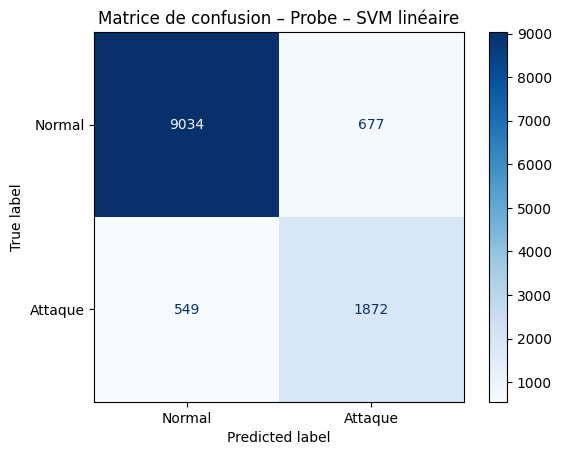

TN=9034 | FP=677 | FN=549 | TP=1872
R2L – temps entraînement : 23.5 s

===== R2L | SVM linéaire =====
              precision    recall  f1-score   support

      Normal       0.79      1.00      0.88      9711
     Attaque       0.90      0.09      0.16      2885

    accuracy                           0.79     12596
   macro avg       0.84      0.54      0.52     12596
weighted avg       0.81      0.79      0.72     12596



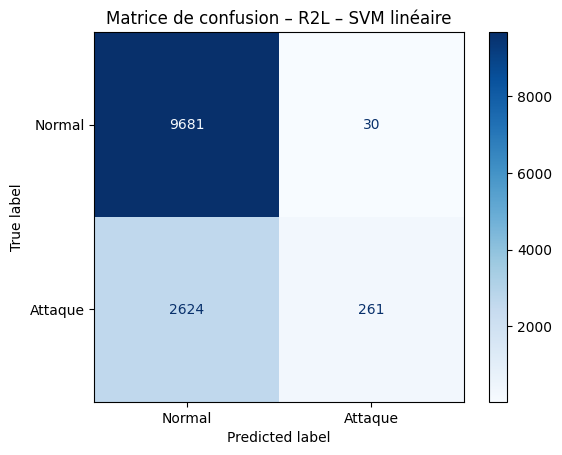

TN=9681 | FP=30 | FN=2624 | TP=261
U2R – temps entraînement : 2.5 s

===== U2R | SVM linéaire =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      9711
     Attaque       0.80      0.36      0.49        67

    accuracy                           0.99      9778
   macro avg       0.90      0.68      0.75      9778
weighted avg       0.99      0.99      0.99      9778



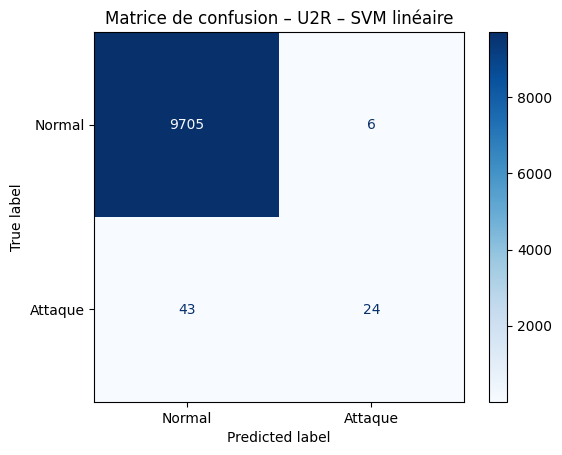

TN=9705 | FP=6 | FN=43 | TP=24


In [ ]:
# Initialisation des structures pour stocker les modèles Support Vector Machine (SVM)
svm_models = {}
svm_predictions = {}

# Entraînement et évaluation de SVM avec un noyau linéaire
for family, data in family_data.items():
    # Configuration du modèle SVM avec marge souple C=1.0 et noyau linéaire
    model = SVC(kernel="linear", C=1.0, random_state=0)

    # Entraînement sur les données d'apprentissage standardisées
    start = time.time()
    model.fit(data["X_train"], data["y_train"])
    elapsed = time.time() - start

    # Prédiction sur les données de test standardisées
    prediction = model.predict(data["X_test"])

    # Enregistrement des modèles entraînés et des sorties associées
    svm_models[family] = model
    svm_predictions[family] = prediction
    print(f"{family} – temps entraînement : {elapsed:.1f} s")

    # Calcul des métriques d'évaluation et affichage graphique des performances de SVM
    evaluate_model(
        family, "SVM linéaire",
        data["y_test"], prediction, data["attack_code"]
    )

## Étape 14 – Combiner les modèles avec VotingClassifier

L’apprentissage par ensemble combine plusieurs classificateurs. Ici, le notebook original utilise un vote majoritaire (*hard voting*) entre Random Forest, KNN et SVM.

Pour chaque famille, chaque modèle vote « normal » ou « attaque ». La classe qui reçoit le plus de votes devient la prédiction finale.


DoS – temps entraînement ensemble : 53.4 s

===== DoS | Voting RF + KNN + SVM =====
              precision    recall  f1-score   support

      Normal       0.85      0.99      0.92      9711
     Attaque       0.99      0.77      0.87      7460

    accuracy                           0.90     17171
   macro avg       0.92      0.88      0.89     17171
weighted avg       0.91      0.90      0.90     17171



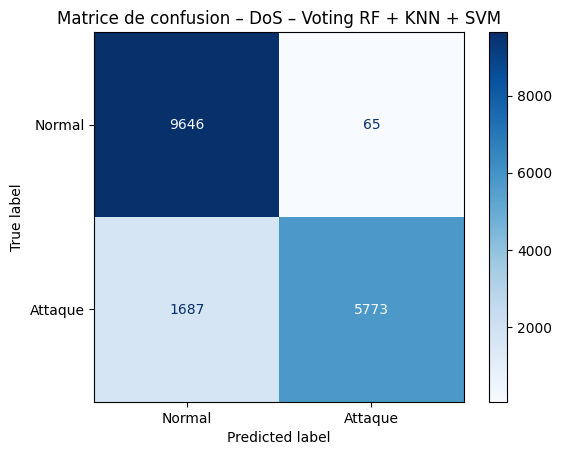

TN=9646 | FP=65 | FN=1687 | TP=5773
Probe – temps entraînement ensemble : 51.8 s

===== Probe | Voting RF + KNN + SVM =====
              precision    recall  f1-score   support

      Normal       0.93      0.97      0.95      9711
     Attaque       0.85      0.69      0.76      2421

    accuracy                           0.91     12132
   macro avg       0.89      0.83      0.85     12132
weighted avg       0.91      0.91      0.91     12132



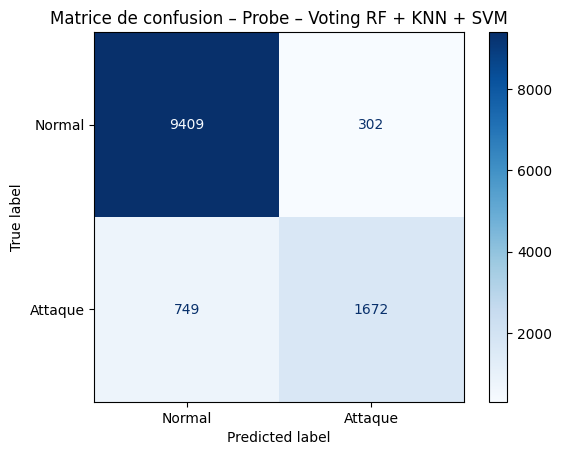

TN=9409 | FP=302 | FN=749 | TP=1672
R2L – temps entraînement ensemble : 21.9 s

===== R2L | Voting RF + KNN + SVM =====
              precision    recall  f1-score   support

      Normal       0.78      1.00      0.88      9711
     Attaque       1.00      0.05      0.09      2885

    accuracy                           0.78     12596
   macro avg       0.89      0.52      0.48     12596
weighted avg       0.83      0.78      0.70     12596



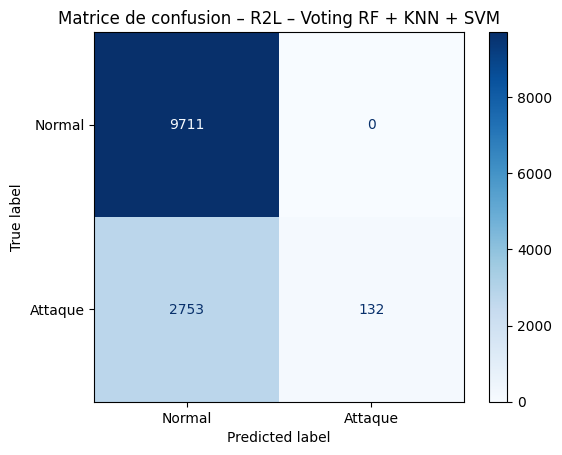

TN=9711 | FP=0 | FN=2753 | TP=132
U2R – temps entraînement ensemble : 5.1 s

===== U2R | Voting RF + KNN + SVM =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      9711
     Attaque       0.84      0.31      0.46        67

    accuracy                           0.99      9778
   macro avg       0.92      0.66      0.73      9778
weighted avg       0.99      0.99      0.99      9778



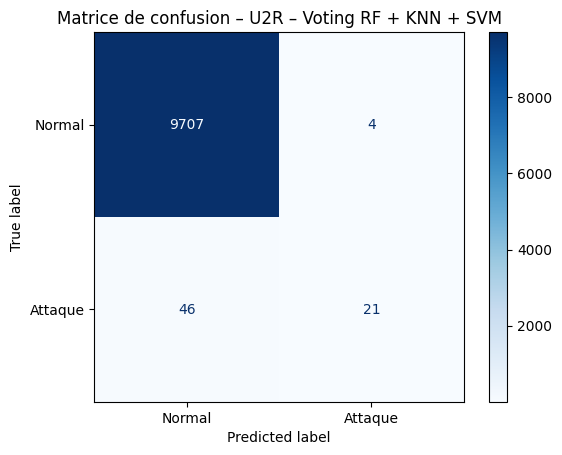

TN=9707 | FP=4 | FN=46 | TP=21


In [ ]:
# Initialisation des dictionnaires pour stocker les modèles d'ensemble et leurs prédictions
voting_models = {}
voting_predictions = {}

# Parcours de chaque famille d'attaques (DoS, Probe, R2L, U2R)
for family, data in family_data.items():
    # Création du classificateur par vote majoritaire (VotingClassifier)
    # Il combine les trois modèles entraînés précédemment sur cette famille
    model = VotingClassifier(
        estimators=[
            ("rf", rf_models[family]),   # Modèle Random Forest
            ("knn", knn_models[family]), # Modèle K-Nearest Neighbors
            ("svm", svm_models[family])  # Modèle Support Vector Machine
        ],
        voting="hard", # 'hard' indique un vote majoritaire strict sur les classes prédites
        n_jobs=-1      # Utilisation de tous les cœurs CPU disponibles pour accélérer le calcul
    )

    # Mesure du temps de début de l'entraînement
    start = time.time()
    # Entraînement de l'ensemble (VotingClassifier) sur les données d'apprentissage de la famille
    model.fit(data["X_train"], data["y_train"])
    # Calcul du temps écoulé pour l'entraînement
    elapsed = time.time() - start
    # Génération des prédictions sur le jeu de test standardisé pour cette famille
    prediction = model.predict(data["X_test"])

    # Sauvegarde du modèle entraîné et de ses prédictions dans les dictionnaires dédiés
    voting_models[family] = model
    voting_predictions[family] = prediction

    # Affichage du temps d'entraînement global de l'ensemble
    print(f"{family} – temps entraînement ensemble : {elapsed:.1f} s")

    # Évaluation des performances du modèle d'ensemble à l'aide de la fonction d'évaluation globale
    evaluate_model(
        family, "Voting RF + KNN + SVM",
        data["y_test"], prediction, data["attack_code"]
    )

## Étape 15 – Comparer les modèles

Nous rassemblons les résultats calculés dans les étapes précédentes. Le but n’est pas de choisir automatiquement le modèle avec la meilleure Accuracy, mais d’étudier également le Recall et le F1-score de la classe Attaque.


In [ ]:
# Conversion de la liste de dictionnaires de métriques en un DataFrame structuré pour l'analyse
results_df = pd.DataFrame(results)

# Tri hiérarchique des modèles par Famille, puis par F1-score décroissant
summary = results_df.sort_values(
    ["Famille", "F1 attaque"], ascending=[True, False]
).reset_index(drop=True)

# Affichage du tableau complet des métriques de synthèse avec arrondi à 4 décimales
display(summary.round(4))

# Pivotage du tableau pour visualiser directement le F1-score de chaque modèle par famille d'attaque
pivot_f1 = summary.pivot(
    index="Famille", columns="Modèle", values="F1 attaque"
)
display(pivot_f1.round(3))

,Famille,Modèle,Accuracy,Precision attaque,Recall attaque,F1 attaque
0,DoS,KNN,0.9176,0.9857,0.8223,0.8966
1,DoS,Voting RF + KNN + SVM,0.8980,0.9889,0.7739,0.8683
2,DoS,Random Forest – toutes variables,0.8926,0.9863,0.7634,0.8607
3,DoS,Random Forest – 13 variables RFE,0.8919,0.9863,0.7618,0.8596
4,DoS,SVM linéaire,0.8869,0.9345,0.7954,0.8594
5,Probe,KNN,0.9175,0.8453,0.7179,0.7764
6,Probe,Voting RF + KNN + SVM,0.9134,0.8470,0.6906,0.7609
7,Probe,SVM linéaire,0.8989,0.7344,0.7732,0.7533
8,Probe,Random Forest – toutes variables,0.9022,0.8718,0.5981,0.7095
9,Probe,Random Forest – 13 variables RFE,0.9012,0.8699,0.5936,0.7056


Modèle,KNN,Random Forest – 13 variables RFE,Random Forest – toutes variables,SVM linéaire,Voting RF + KNN + SVM
Famille,,,,,
DoS,0.897,0.860,0.861,0.859,0.868
Probe,0.776,0.706,0.709,0.753,0.761
R2L,0.103,0.182,0.087,0.164,0.088
U2R,0.495,0.139,0.256,0.495,0.457


### Questions d’analyse

1. Le même algorithme est-il le meilleur pour les quatre familles ?
2. Quel modèle minimise le mieux les faux négatifs ? Appuyez-vous sur le Recall de la classe Attaque.
3. Est-ce que le VotingClassifier améliore systématiquement les résultats ?
4. Pourquoi une Accuracy élevée peut-elle être trompeuse ?
5. Pour un SOC, préféreriez-vous un modèle avec un Recall élevé mais davantage de faux positifs, ou l’inverse ? Justifiez selon le contexte.

## Étape 16 – Validation croisée (complément méthodologique)

Le notebook d’origine calculait plusieurs validations croisées sur les tableaux `*_test`. Ce n’est pas la bonne séparation pour conserver un test indépendant : la validation croisée doit être exécutée sur le jeu d’entraînement. Le jeu de test officiel ne sert qu’à l’évaluation finale.

Pour éviter une durée excessive, on illustre ici une validation croisée stratifiée à 5 plis sur Random Forest pour DoS. Elle peut être répétée pour les autres familles et modèles en exercice.


In [ ]:
# Détermination de la famille cible de l'illustration méthodologique (DoS)
family = "DoS"
data = family_data[family]

# Configuration de la validation croisée stratifiée à 5 plis (StratifiedKFold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Initialisation du modèle Random Forest à valider
cv_model = RandomForestClassifier(
    n_estimators=10, n_jobs=-1, random_state=42
)

# Exécution de la validation croisée et collecte des métriques clés de performance sur chaque pli
cv_scores = cross_validate(
    cv_model,
    data["X_train"],
    data["y_train"],
    cv=cv,
    scoring=["accuracy", "precision_macro", "recall_macro", "f1_macro"],
    n_jobs=-1
)

# Calcul et affichage des moyennes et intervalles de confiance (2 * écart-type) pour chaque métrique
for metric in ["accuracy", "precision_macro", "recall_macro", "f1_macro"]:
    values = cv_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {2 * values.std():.4f})")

accuracy: 0.9997 (+/- 0.0002)
precision_macro: 0.9997 (+/- 0.0002)
recall_macro: 0.9997 (+/- 0.0002)
f1_macro: 0.9997 (+/- 0.0002)


## Étape 17 – Travail à rendre

Fournir le notebook Colab exécuté (avec les sorties visibles) et une courte synthèse répondant aux questions suivantes :

1. Expliquer la différence entre DoS, Probe, R2L et U2R.
2. Expliquer pourquoi on entraîne quatre classificateurs binaires dans ce TP.
3. Comparer Random Forest avec toutes les variables et Random Forest avec les 13 variables RFE.
4. Comparer Random Forest, KNN, SVM et VotingClassifier pour une famille au choix.
5. Présenter une matrice de confusion et expliquer TN, FP, FN et TP.
6. Identifier la famille pour laquelle le système obtient le Recall le plus faible et proposer une explication.
7. Expliquer les trois corrections de méthode apportées : encodage train/test, StandardScaler, validation croisée.
8. Expliquer pourquoi les résultats obtenus sur NSL-KDD ne prouvent pas qu’un IDS est prêt à être déployé sur un réseau actuel.

### Limites à mentionner

- NSL-KDD est un benchmark historique, pas un reflet complet du trafic réseau actuel.
- Les modèles apprennent des patterns propres à ce dataset.
- Les quatre classificateurs sont spécialisés dans une famille, et ne constituent pas à eux seuls une chaîne de détection en production.
- Les métriques varient selon l’environnement d’exécution et les corrections de prétraitement.

**Fin du TP.**